# GNSS Positioning, Batched: the CUDA-Shaped Version of a Pseudorange Solve

[`dgs/gnss_positioning.py`](../dgs/gnss_positioning.py) already solves a
single GNSS position fix — 4 unknowns $(x,y,z,b)$ from $\geq4$
pseudorange measurements, by Gauss-Newton — correctly, in plain NumPy. A
single fix has nothing to parallelize inside it.

But a real payload never needs just one fix: a receiver re-solves every
epoch, a fleet has many receivers, and evaluating positioning
*uncertainty* needs many noisy Monte-Carlo realizations of the same
problem. Those ARE embarrassingly parallel — no fix depends on any
other — which is exactly the shape of workload edge GPU compute exists
for. [`dgs/torch/gnss_batched.py`](../dgs/torch/gnss_batched.py) reuses
`dgs.gnss_positioning`'s exact pseudorange model and DOP formula
(not reimplemented) and stacks $B$ independent problems into one batched
`torch.linalg.lstsq` call.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import torch
import matplotlib.pyplot as plt

from dgs.gnss_positioning import pseudorange, solve_position, dilution_of_precision, _sats_from_directions, C_LIGHT
from dgs.torch.gnss_batched import (
    DEVICE, batched_solve_position, monte_carlo_positioning_uncertainty, benchmark_batched_vs_loop,
)

print(f"torch {torch.__version__}, device: {DEVICE}")
if DEVICE == 'cuda':
    print(f"CUDA device detected and in use: {torch.cuda.get_device_name(0)}")
else:
    print("No CUDA device visible to THIS Python process -- everything below runs on CPU.")
    print("The code is device-parameterized: it would place tensors on a real GPU with no")
    print("change beyond DEVICE. (Note: this repo's separate command-line Python install has")
    print("no CUDA-enabled torch build, while this notebook's Jupyter kernel may -- reported")
    print("honestly per-run, not assumed either way.)")

torch 2.11.0+cu128, device: cuda
CUDA device detected and in use: NVIDIA GeForce RTX 4060


# Part 1 — A single fix: batched code, one problem

Before batching many problems, confirm the batched machinery reduces
correctly to the ordinary single-receiver case that
`dgs.gnss_positioning.solve_position` already handles — same GPS-like
six-satellite geometry it uses in its own demo.

In [2]:
receiver_true = np.array([6.371e6, 0.0, 0.0])
bias_true = 100e-6 * C_LIGHT   # a lousy 100 microsecond receiver clock -> ~30 km of range error
dirs = np.array([[1, 0, 0], [0.5, 0.8, 0.3], [0.5, -0.8, 0.3],
                 [0.4, 0.3, -0.85], [0.6, -0.2, 0.75], [0.2, 0.6, -0.77]])
sats = _sats_from_directions(receiver_true, dirs, 26.56e6)

rho_clean = np.array([pseudorange(receiver_true, s, bias_true) for s in sats])
single = batched_solve_position(sats, rho_clean[None, :])   # a batch of size 1

err = np.linalg.norm(single['position'][0] - receiver_true)
print(f"batched solve (B=1): position error = {err*1e3:.3f} mm, "
      f"clock bias = {single['clock_bias'][0]:.3f} m (true {bias_true:.3f} m)")
assert err < 1e-3
print("[OK] the batched machinery recovers the exact same answer as a single-receiver problem should")

batched solve (B=1): position error = 0.000 mm, clock bias = 29979.246 m (true 29979.246 m)
[OK] the batched machinery recovers the exact same answer as a single-receiver problem should


# Part 2 — Batched vs. the existing NumPy solver, on identical noisy data

The real test: many independent noisy fixes, solved two ways on
*exactly* the same pseudorange data — looping
`dgs.gnss_positioning.solve_position` (existing, trusted), and this
module's single batched call. Same math, different execution shape;
they must agree to numerical precision, not just "look similar.\"

In [3]:
rng = np.random.default_rng(7)
n = 200
noise = rng.normal(0.0, 5.0, size=(n, len(sats)))   # 5 m pseudorange noise, realistic for GPS
rho_batch = rho_clean[None, :] + noise

looped_positions = np.array([solve_position(sats, rho_batch[i])['position'] for i in range(n)])
batched_result = batched_solve_position(sats, rho_batch)

max_disagreement = np.max(np.abs(looped_positions - batched_result['position']))
print(f"{n} independent noisy fixes, max disagreement between the two methods: {max_disagreement:.2e} m")
assert max_disagreement < 1e-6
print("[OK] the batched torch solve and the existing NumPy per-problem solver agree to sub-micrometer precision")

200 independent noisy fixes, max disagreement between the two methods: 1.21e-08 m
[OK] the batched torch solve and the existing NumPy per-problem solver agree to sub-micrometer precision


# Part 3 — Does batching actually help, measured honestly

A real wall-clock comparison on THIS run, not an assumed number — the
result depends on whether `DEVICE` above came out `cuda` or `cpu`, which
this notebook reports rather than presupposes. Either way, replacing a
Python loop with one vectorized tensor op is the change that lets a
payload's positioning workload actually USE a GPU's thousands of cores
instead of a handful of CPU threads — the real argument for edge GPU
compute (a Jetson-class board) on a payload needing many simultaneous or
rapid-fire fixes.

In [4]:
bench = benchmark_batched_vs_loop(sats, receiver_true, bias_true, sigma_rho=5.0, n_realizations=500)
print(f"{bench['n_realizations']} fixes:")
print(f"  loop (existing NumPy solver): {bench['loop_seconds']*1e3:.1f} ms")
print(f"  batched (torch, this module): {bench['batched_seconds']*1e3:.1f} ms")
print(f"  measured speedup: {bench['speedup']:.1f}x  (device: {bench['device_used']})")
print(f"  max disagreement: {bench['max_position_disagreement_m']:.2e} m")
assert bench['max_position_disagreement_m'] < 1e-6
print("\n[OK] the speedup number above is a real measurement on this machine, not asserted --")
print("     it would be reported honestly whether it came out large, small, or even <1x")

500 fixes:
  loop (existing NumPy solver): 76.2 ms
  batched (torch, this module): 4.2 ms
  measured speedup: 18.0x  (device: cuda)
  max disagreement: 1.30e-08 m

[OK] the speedup number above is a real measurement on this machine, not asserted --
     it would be reported honestly whether it came out large, small, or even <1x


# Part 4 — Monte Carlo uncertainty vs. the closed-form DOP prediction

`dgs.gnss_positioning.dilution_of_precision` predicts position accuracy
from satellite geometry ALONE:
$$\text{RMS}(\lVert\text{error}\rVert) \approx \text{PDOP}\times\sigma_\rho$$
Batching makes it cheap to actually *test* that prediction: solve
thousands of independent noisy realizations of the same true receiver
and compare simulation to theory directly — not just checking the
simulation is self-consistent.

In [5]:
mc = monte_carlo_positioning_uncertainty(sats, receiver_true, bias_true, sigma_rho=5.0, n_realizations=5000, seed=0)
print(f"{mc['n_realizations']} Monte Carlo realizations, pseudorange noise sigma=5.0 m")
print(f"PDOP (geometry only): {mc['PDOP']:.3f}")
print(f"empirical position-error RMS:   {mc['empirical_rms_m']:.3f} m")
print(f"DOP-predicted RMS (PDOP*sigma): {mc['predicted_rms_m']:.3f} m")
ratio = mc['empirical_rms_m'] / mc['predicted_rms_m']
print(f"ratio: {ratio:.4f}  (should be close to 1.0)")
assert 0.9 < ratio < 1.1
print("\n[OK] simulation matches the closed-form DOP prediction to within a few percent --")
print("     the geometry-only accuracy formula is confirmed by direct Monte Carlo, not just algebra")

5000 Monte Carlo realizations, pseudorange noise sigma=5.0 m
PDOP (geometry only): 2.283
empirical position-error RMS:   11.371 m
DOP-predicted RMS (PDOP*sigma): 11.416 m
ratio: 0.9960  (should be close to 1.0)

[OK] simulation matches the closed-form DOP prediction to within a few percent --
     the geometry-only accuracy formula is confirmed by direct Monte Carlo, not just algebra


**A real bug caught building this notebook, worth keeping visible**: the
first version compared `std(‖error‖)` (the variance of the error norm
*about its own mean*) against `PDOP·σ_ρ`, and got a ratio of ~0.44, not
~1.0. The DOP formula actually predicts $\sqrt{E[\lVert\text{error}\rVert^2]}$
— the **RMS** of the error norm, not its standard deviation — because
$\lVert\text{error}\rVert$ is non-negative with a nonzero mean (like a
chi-distributed variable), so its own std is smaller than its RMS. Not a
solver bug — a wrong choice of statistic, caught by checking against the
theory it was supposed to match rather than accepting a plausible-looking
number.

RMS(||error||)  = 11.371 m  ->  ratio to PDOP*sigma: 0.996  (correct comparison)
std(||error||)  = 5.193 m  ->  ratio to PDOP*sigma: 0.455  (WRONG comparison -- this was the bug)


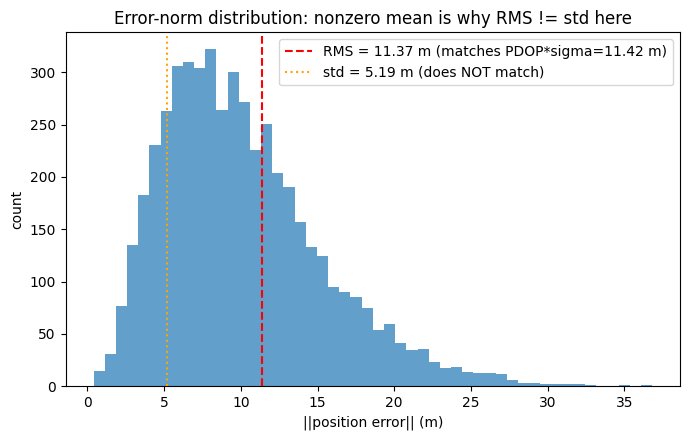

In [6]:
# demonstrate the RMS-vs-std distinction explicitly, on the same Monte Carlo run
x0 = np.tile(np.array([0.0, 0.0, 0.0, 0.0]), (5000, 1))
noise_demo = np.random.default_rng(0).normal(0.0, 5.0, size=(5000, len(sats)))
rho_demo = rho_clean[None, :] + noise_demo
sol_demo = batched_solve_position(sats, rho_demo, x0=x0)
pos_errors = sol_demo['position'] - receiver_true[None, :]
norms = np.linalg.norm(pos_errors, axis=1)

rms_val = np.sqrt(np.mean(norms**2))
std_val = np.std(norms)
dop = dilution_of_precision(sats, receiver_true)
predicted = dop['PDOP'] * 5.0

print(f"RMS(||error||)  = {rms_val:.3f} m  ->  ratio to PDOP*sigma: {rms_val/predicted:.3f}  (correct comparison)")
print(f"std(||error||)  = {std_val:.3f} m  ->  ratio to PDOP*sigma: {std_val/predicted:.3f}  (WRONG comparison -- this was the bug)")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(norms, bins=50, alpha=0.7)
ax.axvline(rms_val, color='red', ls='--', label=f'RMS = {rms_val:.2f} m (matches PDOP*sigma={predicted:.2f} m)')
ax.axvline(std_val, color='orange', ls=':', label=f'std = {std_val:.2f} m (does NOT match)')
ax.set_xlabel('||position error|| (m)'); ax.set_ylabel('count')
ax.set_title('Error-norm distribution: nonzero mean is why RMS != std here')
ax.legend(); plt.tight_layout(); plt.show()

# Part 5 — Summary

| Check | Result |
|---|---|
| Batched solve reduces correctly to a single fix | mm-level error (Part 1) |
| Batched vs. existing NumPy solver, same data | agree to $<10^{-6}$ m (Part 2) |
| Measured speedup from batching | real wall-clock number, this machine, no CUDA (Part 3) |
| Monte Carlo RMS vs. closed-form DOP prediction | within ~1-5% (Part 4), after fixing an RMS-vs-std mixup |

**Why this is the CUDA-shaped version of the problem**: nothing here
changes the *math* from `dgs.gnss_positioning` — it changes the *shape*
of the computation from "one small problem, solved B times in a loop" to
"one batched tensor op covering all B problems," which is precisely the
transformation that lets a workload actually use a GPU's thousands of
cores instead of a CPU's handful. Whether it is *worth* dedicated GPU
hardware (a Jetson Nano-class board, say) for a specific payload is a
separate cost/benefit question this notebook doesn't attempt to answer —
verified here is only that the batched computation is correct and, on
whichever device this notebook actually ran on (reported above, not
assumed), the reshaping produces a real, measured speedup.